# Bài thực hành 6: Máy vectơ hỗ trợ (SVM)

**Sinh viên:** Nguyễn Thành Phong · **Học phần:** Học máy ứng dụng · **Giảng viên:** ThS. Nguyễn Thái Anh

Dữ liệu (số liệu mô phỏng dùng cho giảng dạy):
- 24 điểm hai cụm (mục 2, bài tập 1–2): tự sinh bằng `make_blobs(centers=[[2, 2], [6, 6]], cluster_std=0.9, random_state=0)`, không cần tệp.
- `data/sinh_vien.csv`: dùng lại từ bài 2, cột `gio_on`, `diem_giua_ky`, `qua_mon`.
- `data/sinh_vien_mo_rong.csv`: dùng lại từ bài 4, thêm cột `chi_tieu` (nghìn đồng).
- `data/hai_vang_trang.csv`: dùng lại từ bài 4, 300 điểm, cột `x1`, `x2`, `nhan`.
- Bộ chữ số viết tay `load_digits` (1797 ảnh 8 × 8) và dữ liệu `make_classification` của bài tập 6 có sẵn trong scikit-learn.

Đề dùng lại đúng các tệp của bài trước, nên mọi con số in ra khớp tài liệu (xem nhận xét từng mục).

Mỗi mục bên dưới ứng với một tệp trong `code/` (phần bài giảng) hoặc `baitap06/` (phần bài tập).
Chạy các tệp đó từ thư mục `Lab06/`, ví dụ `python baitap06/bai1.py`.

In [1]:
# Chuẩn bị dữ liệu: chạy local thì đọc thẳng, trên Colab thì tải ba tệp lên
import os
CAN_CO = ["data/sinh_vien.csv", "data/sinh_vien_mo_rong.csv",
          "data/hai_vang_trang.csv"]
if not all(os.path.exists(p) for p in CAN_CO):
    from google.colab import files
    files.upload()                         # chon ca ba tep csv
    os.makedirs("data", exist_ok=True)
    for p in CAN_CO:
        if os.path.exists(os.path.basename(p)):
            os.replace(os.path.basename(p), p)
for p in CAN_CO:
    print(f"Co {p} chua?", os.path.exists(p))

Co data/sinh_vien.csv chua? True
Co data/sinh_vien_mo_rong.csv chua? True
Co data/hai_vang_trang.csv chua? True


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC

# Hai màu cố định cho hai lớp, dùng chung cho mọi hình
MAU_1 = "#2a78d6"          # lớp 1
MAU_0 = "#eb6834"          # lớp 0
MAU_CHU = "#52514e"
MAU_HT = "#f2b705"         # vòng khoanh vectơ hỗ trợ
NEN = ["#fbe1d6", "#d6e6f8"]   # nền vùng quyết định của lớp 0 và lớp 1
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MAU_CHU, "axes.grid": True, "grid.color": "#e4e3df",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "lines.linewidth": 2,
})


def ve_bien(ax, mo_hinh, X, y, khung, ten_cot=None, vecto_ht=None, le=True, n=300):
    """Ve vung quyet dinh, duong f(x) = 0 (net lien), hai mep le f(x) = +-1 (net dut),
    cac diem cua tap hoc va khoanh vang cac vecto ho tro (chi so trong X).
    ten_cot = None nghia la mo hinh hoc tren mang numpy, khong co ten cot."""
    (x0, x1), (y0, y1) = khung
    gx, gy = np.meshgrid(np.linspace(x0, x1, n), np.linspace(y0, y1, n))
    luoi = np.c_[gx.ravel(), gy.ravel()]
    if ten_cot is not None:
        luoi = pd.DataFrame(luoi, columns=ten_cot)
    f = mo_hinh.decision_function(luoi).reshape(gx.shape)
    ax.contourf(gx, gy, f, levels=[-1e9, 0, 1e9], colors=NEN)
    ax.contour(gx, gy, f, levels=[0], colors=MAU_CHU, linewidths=1.6)
    if le:
        ax.contour(gx, gy, f, levels=[-1, 1], colors=MAU_CHU, linewidths=1, linestyles="--")
    X = np.asarray(X); y = np.asarray(y)
    for nhan, mau, mk in [(1, MAU_1, "o"), (0, MAU_0, "^")]:
        ax.scatter(X[y == nhan, 0], X[y == nhan, 1], c=mau, marker=mk, s=18,
                   edgecolor="white", linewidth=0.4, zorder=3)
    if vecto_ht is not None:
        ax.scatter(X[vecto_ht, 0], X[vecto_ht, 1], s=110, facecolor="none",
                   edgecolor=MAU_HT, linewidth=1.8, zorder=4)
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.grid(False)

## 1. Đường có lề rộng nhất (`code/g1_le_rong_nhat.py`)

$$f(x) = w_1x_1 + w_2x_2 + b \qquad \text{lề} = \frac{2}{\sqrt{w_1^2 + w_2^2}}$$

SVM đoán lớp 1 khi $f(x) > 0$, lớp 0 khi $f(x) < 0$; hai mép lề là $f(x) = \pm 1$, điểm nằm đúng trên mép lề là vectơ hỗ trợ.

In [3]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

# 24 điểm, hai cụm tách hẳn nhau
X, y = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]],
                  cluster_std=0.9, random_state=0)
y = 1 - y            # lớp 1 là cụm dưới bên trái, giống hình trên slide

# C rất lớn nghĩa là không cho điểm nào nằm trong lề
svm = SVC(kernel="linear", C=1000)
svm.fit(X, y)

w = svm.coef_[0]
b = svm.intercept_[0]
print(f"w1 = {w[0]:.3f}, w2 = {w[1]:.3f}, b = {b:.3f}")
do_dai_w = np.sqrt(w[0] ** 2 + w[1] ** 2)
print(f"Do rong cua le = 2 / {do_dai_w:.4f} = {2 / do_dai_w:.4f}")
print()

# Các vectơ hỗ trợ nằm đúng trên hai mép lề, nơi f(x) bằng 1 hoặc -1
print("So vecto ho tro:", len(svm.support_))
for i in svm.support_:
    f = svm.decision_function(X[i:i + 1])[0]
    print(f"  diem {i:2d}: x1 = {X[i, 0]:.2f}, x2 = {X[i, 1]:.2f},"
          f" lop {y[i]}, f(x) = {f:+.3f}")
print()

# Những điểm khác nằm ngoài lề, nên |f(x)| lớn hơn 1
f_tat_ca = svm.decision_function(X)
ngoai = np.setdiff1d(np.arange(len(X)), svm.support_)
nho_nhat = np.abs(f_tat_ca[ngoai]).min()
print(f"|f(x)| nho nhat cua cac diem khac: {nho_nhat:.3f}")
print()

# Học lại chỉ với các vectơ hỗ trợ
chi_sv = SVC(kernel="linear", C=1000)
chi_sv.fit(X[svm.support_], y[svm.support_])
w2 = chi_sv.coef_[0]
print("Hoc lai chi voi vecto ho tro:")
b2 = chi_sv.intercept_[0]
print(f"  w1 = {w2[0]:.3f}, w2 = {w2[1]:.3f}, b = {b2:.3f}")
print()

# Dự đoán cho hai điểm mới
moi = np.array([[3.0, 3.0], [5.0, 4.5]])
for diem, f, lop in zip(moi, svm.decision_function(moi),
                        svm.predict(moi)):
    print(f"Diem ({diem[0]}, {diem[1]}): f(x) = {f:+.3f}, doan lop {lop}")

w1 = -0.831, w2 = -0.355, b = 4.820
Do rong cua le = 2 / 0.9039 = 2.2126

So vecto ho tro: 3
  diem 18: x1 = 5.20, x2 = 4.22, lop 0, f(x) = -1.000
  diem 10: x1 = 2.88, x2 = 4.02, lop 1, f(x) = +1.000
  diem 13: x1 = 3.59, x2 = 2.36, lop 1, f(x) = +1.000

|f(x)| nho nhat cua cac diem khac: 1.059

Hoc lai chi voi vecto ho tro:
  w1 = -0.831, w2 = -0.355, b = 4.821

Diem (3.0, 3.0): f(x) = +1.262, doan lop 1
Diem (5.0, 4.5): f(x) = -0.933, doan lop 0


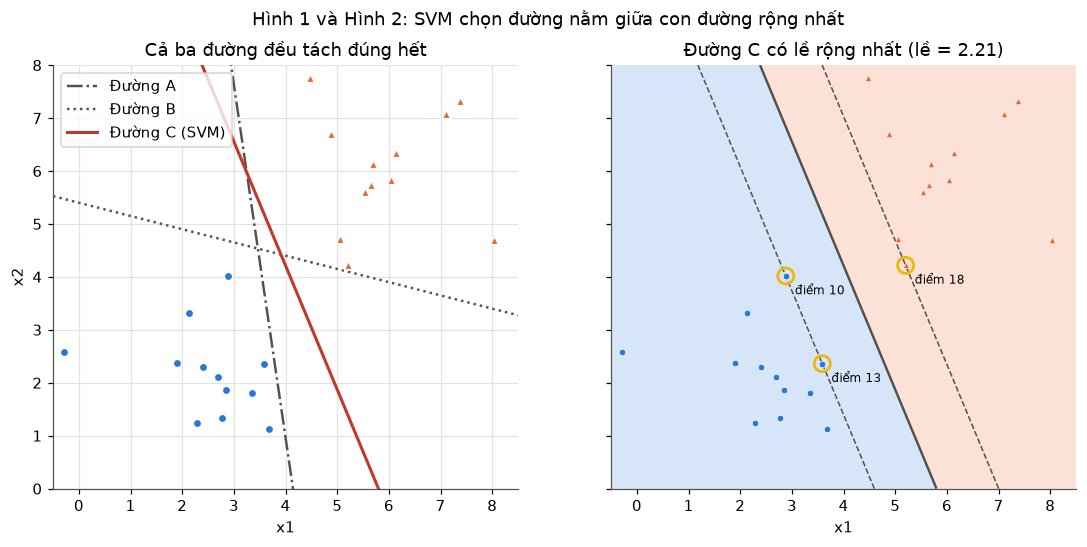

In [4]:
# Hình 1: ba đường cùng tách đúng hết 24 điểm; Hình 2: đường của SVM với lề và vectơ hỗ trợ
def nguong_tach(huong, ti_le):
    """Duong vuong goc voi huong, dat o ti_le giua hai lop (0 = sat lop 1, 1 = sat lop 0)."""
    p = X @ huong
    a, b_ = p[y == 1].max(), p[y == 0].min()
    assert a < b_, "huong nay khong tach duoc"
    return a + ti_le * (b_ - a)

xs = np.linspace(-0.5, 8.5, 50)
cac_duong = {"Đường A": (np.array([1.0, 0.15]), 0.12), "Đường B": (np.array([0.25, 1.0]), 0.85)}
fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
ax = axs[0]
for (ten, (h, t)), kieu in zip(cac_duong.items(), ["-.", ":"]):
    c = nguong_tach(h, t)
    ax.plot(xs, (c - h[0] * xs) / h[1], kieu, color=MAU_CHU, lw=1.6, label=ten)
ax.plot(xs, -(w[0] * xs + b) / w[1], color="#c0392b", lw=2, label="Đường C (SVM)")
for nhan, mau, mk in [(1, MAU_1, "o"), (0, MAU_0, "^")]:
    ax.scatter(X[y == nhan, 0], X[y == nhan, 1], c=mau, marker=mk, s=30, edgecolor="white", zorder=3)
ax.set_xlim(-0.5, 8.5); ax.set_ylim(0, 8); ax.set_xlabel("x1"); ax.set_ylabel("x2")
ax.legend(loc="upper left"); ax.set_title("Cả ba đường đều tách đúng hết")
ve_bien(axs[1], svm, X, y, ((-0.5, 8.5), (0, 8)), vecto_ht=svm.support_)
for i in svm.support_:
    axs[1].annotate(f"điểm {i}", X[i], xytext=(6, -12), textcoords="offset points", fontsize=8)
axs[1].set_xlabel("x1"); axs[1].set_title(f"Đường C có lề rộng nhất (lề = {2 / do_dai_w:.2f})")
fig.suptitle("Hình 1 và Hình 2: SVM chọn đường nằm giữa con đường rộng nhất"); plt.show()

**Nhận xét.** Khớp tài liệu từng con số: $w_1 = -0.831$, $w_2 = -0.355$, $b = 4.820$, $\lVert w \rVert = 0.9039$, nên lề rộng 2 / 0.9039 = **2.2126**. Có đúng **3 vectơ hỗ trợ**: điểm 18 của lớp 0 với $f(x) = -1.000$, điểm 10 và điểm 13 của lớp 1 với $f(x) = +1.000$. Chúng nằm đúng trên hai mép lề (khoanh vàng ở Hình 2), còn 21 điểm khác có $|f(x)| \ge 1.059$, tức nằm hẳn ngoài lề.

Hình 1 cho thấy vì sao phải có tiêu chí "lề rộng nhất". Đường A và đường B tách đúng cả 24 điểm nhưng một đường sát lớp 1, một đường sát lớp 0; chỉ cần một điểm mới lệch một chút là bị đoán sai. Đường C của SVM nằm giữa con đường rộng 2.21 đơn vị giữa hai lớp.

Học lại chỉ với 3 vectơ hỗ trợ được $w$ giống hệt và $b = 4.821$ (lệch 0.001 do bộ giải chỉ dừng ở sai số cho phép). 21 điểm còn lại không góp phần nào vào đường ranh giới: đây là điểm khác cơ bản với hồi quy logistic, nơi mọi điểm đều kéo đường thẳng.

Điểm (3, 3) có $f = +1.262 > 1$: lớp 1, nằm ngoài lề, chắc chắn. Điểm (5, 4.5) có $f = -0.933$: âm nên đoán lớp 0, nhưng $|f| < 1$ nghĩa là nó nằm **trong lề**, gần ranh giới, dự đoán kém chắc chắn. $f(x)$ chỉ là khoảng cách có dấu (nhân với $\lVert w \rVert$), không phải xác suất.

## 2. Lề mềm và tham số C (`code/g2_tham_so_c.py`)

C là mức phạt cho mỗi điểm vi phạm lề: C nhỏ thì lề rộng, nhiều điểm vi phạm; C lớn thì lề hẹp. Mọi điểm nằm trên mép lề, trong lề hoặc sai phía đều là vectơ hỗ trợ.

In [5]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

df = pd.read_csv("data/sinh_vien.csv")
X = df[["gio_on", "diem_giua_ky"]]
y = df["qua_mon"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("Tap hoc co", len(X_tr), "ban")
print("     C    so vecto HT   do rong le   tap hoc   tap kiem tra")
for C in [0.01, 0.1, 1, 10, 100]:
    mh = make_pipeline(StandardScaler(),
                       SVC(kernel="linear", C=C))
    mh.fit(X_tr, y_tr)
    svm = mh[-1]                    # bước cuối của pipeline là SVM
    le = 2 / np.linalg.norm(svm.coef_[0])
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {C:6}    {len(svm.support_):6d}       {le:6.2f}"
          f"     {a_hoc:.4f}    {a_kt:.4f}")
print()

# Bộ sinh viên mở rộng có thêm cột chi tiêu, tính bằng nghìn đồng
df3 = pd.read_csv("data/sinh_vien_mo_rong.csv")
X3 = df3[["gio_on", "diem_giua_ky", "chi_tieu"]]
y3 = df3["qua_mon"]
X3_tr, X3_te, y3_tr, y3_te = train_test_split(
    X3, y3, test_size=0.25, random_state=17, stratify=y3
)
tho = SVC().fit(X3_tr, y3_tr)
chuan = make_pipeline(StandardScaler(), SVC()).fit(X3_tr, y3_tr)
print("Ba cot, kernel RBF mac dinh")
print(f"  Doan bua ca lop qua : {y3_te.mean():.4f}")
print(f"  Khong chuan hoa     : "
      f"{accuracy_score(y3_te, tho.predict(X3_te)):.4f}")
print(f"  Co chuan hoa        : "
      f"{accuracy_score(y3_te, chuan.predict(X3_te)):.4f}")

Tap hoc co 90 ban
     C    so vecto HT   do rong le   tap hoc   tap kiem tra
    0.01        74         3.84     0.8556    0.8667
     0.1        44         1.70     0.8889    0.9000
       1        31         1.29     0.8778    0.9000
      10        28         1.06     0.9000    0.9000
     100        27         1.05     0.9000    0.9000

Ba cot, kernel RBF mac dinh
  Doan bua ca lop qua : 0.6000
  Khong chuan hoa     : 0.6000
  Co chuan hoa        : 0.9000


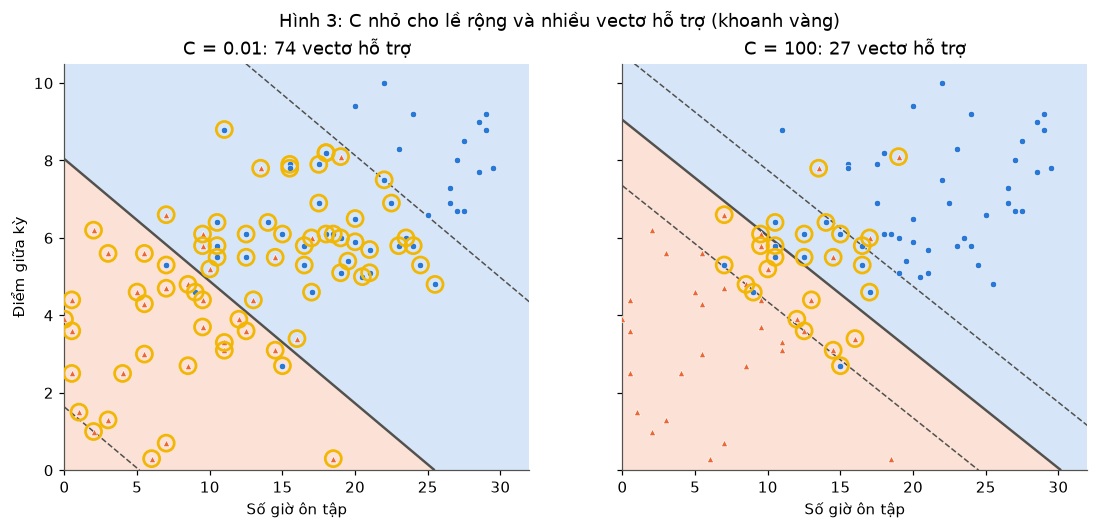

Do lech chuan cua ba cot tren tap hoc:
gio_on             8.13
diem_giua_ky       2.16
chi_tieu        1720.71


In [6]:
# Hình 3: cùng một tập học với C = 0.01 và C = 100 (vẽ ở thang đo gốc, SVM học trên dữ liệu đã chuẩn hoá)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, C in zip(axs, [0.01, 100]):
    mh = make_pipeline(StandardScaler(), SVC(kernel="linear", C=C)).fit(X_tr, y_tr)
    ve_bien(ax, mh, X_tr, y_tr, ((0, 32), (0, 10.5)), ten_cot=["gio_on", "diem_giua_ky"],
            vecto_ht=mh[-1].support_)
    ax.set_title(f"C = {C}: {len(mh[-1].support_)} vectơ hỗ trợ"); ax.set_xlabel("Số giờ ôn tập")
axs[0].set_ylabel("Điểm giữa kỳ")
fig.suptitle("Hình 3: C nhỏ cho lề rộng và nhiều vectơ hỗ trợ (khoanh vàng)"); plt.show()

print("Do lech chuan cua ba cot tren tap hoc:")
print(X3_tr.std().round(2).to_string())

**Nhận xét.** Hai bảng khớp tài liệu từng con số.

**Bảng thứ nhất.** Khi C tăng từ 0.01 lên 100, số vectơ hỗ trợ giảm từ **74 xuống 27** (trên 90 bạn), lề (đo trên dữ liệu đã chuẩn hoá) hẹp từ **3.84 xuống 1.05**, accuracy tập kiểm tra tăng từ 0.8667 lên 0.9000 rồi đứng yên. Hình 3 vẽ đúng điều đó: với C = 0.01, hai mép lề cách nhau xa tới mức gần như mọi bạn ở vùng giữa đều nằm trong lề và thành vectơ hỗ trợ; mức phạt quá nhẹ nên đường ranh giới còn hơi lệch, đẩy vài bạn qua sai phía. Với C = 100, lề hẹp lại và chỉ những bạn sát ranh giới, hoặc nằm sai phía (những bạn ôn nhiều mà vẫn rớt), mới còn khoanh vàng. Từ C = 0.1 trở lên, accuracy tập kiểm tra không đổi (0.9000, bằng hồi quy logistic của bài 2): với biên thẳng và hai cột, C chỉ xoay đường ranh giới chút ít.

**Bảng thứ hai.** Không chuẩn hoá, SVM kernel RBF chỉ đạt **0.6000**, đúng bằng mức đoán bừa cả lớp qua (60% bạn qua môn); có chuẩn hoá thì đạt **0.9000**. Độ lệch chuẩn in ở trên giải thích: chi tiêu lệch chuẩn khoảng 1721 (nghìn đồng), giờ ôn chỉ 8.13 và điểm giữa kỳ 2.16. Khoảng cách $\lVert x - z \rVert$ trong kernel RBF gần như chỉ còn là chênh lệch chi tiêu, một cột không liên quan tới việc qua môn, nên mô hình rơi về đoán lớp đông nhất. Cùng cái bẫy của KNN ở bài 4: lề và kernel đều là khoảng cách, nên luôn đặt `StandardScaler()` trước `SVC()` trong một pipeline.

## 3. Kernel và biên cong (`code/g3_kernel.py`)

$$K(x, z) = e^{-\gamma \lVert x - z \rVert^2}$$

Hai điểm trùng nhau thì $K = 1$, càng xa nhau thì $K$ càng gần 0. Đây là kernel mặc định của `SVC`.

In [7]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Phần 1: dữ liệu một chiều, lớp 1 nằm giữa, lớp 0 ở hai đầu
x = np.array([-4.0, -3.4, -2.8, -2.2, -1.2, -0.7, -0.2,
              0.3, 0.8, 1.3, 2.3, 2.9, 3.5, 4.0])
y = (np.abs(x) < 1.8).astype(int)

# Thử mọi ngưỡng: đoán lớp 1 khi x nhỏ hơn hoặc bằng ngưỡng
tot = max(((x <= t).astype(int) == y).mean() for t in x)
print(f"Mot nguong tren truc x, tot nhat dung {tot:.4f}")

# Thêm cột x bình phương rồi dùng SVM tuyến tính
X_moi = np.c_[x, x ** 2]
svm = SVC(kernel="linear", C=1000).fit(X_moi, y)
print(f"Them cot x^2, SVM tuyen tinh dung {svm.score(X_moi, y):.4f}")
print()

# Phần 2: hai vầng trăng, để kernel tự nâng chiều
df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mo_hinh = {
    "SVM kernel tuyen tinh": SVC(kernel="linear"),
    "SVM kernel da thuc bac 3": SVC(kernel="poly", degree=3),
    "SVM kernel RBF": SVC(kernel="rbf"),
    "Hoi quy logistic": LogisticRegression(),
    "KNN, k = 13": KNeighborsClassifier(n_neighbors=13),
}
print("Hai vang trang, accuracy tren tap kiem tra")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {ten:26s} {acc:.4f}")
print()

rbf = mo_hinh["SVM kernel RBF"]
print("So vecto ho tro cua kernel RBF:", len(rbf.support_),
      "tren", len(X_tr), "diem hoc")

Mot nguong tren truc x, tot nhat dung 0.7143
Them cot x^2, SVM tuyen tinh dung 1.0000

Hai vang trang, accuracy tren tap kiem tra
  SVM kernel tuyen tinh      0.8667
  SVM kernel da thuc bac 3   0.8667
  SVM kernel RBF             0.9200
  Hoi quy logistic           0.8533
  KNN, k = 13                0.9200

So vecto ho tro cua kernel RBF: 89 tren 225 diem hoc


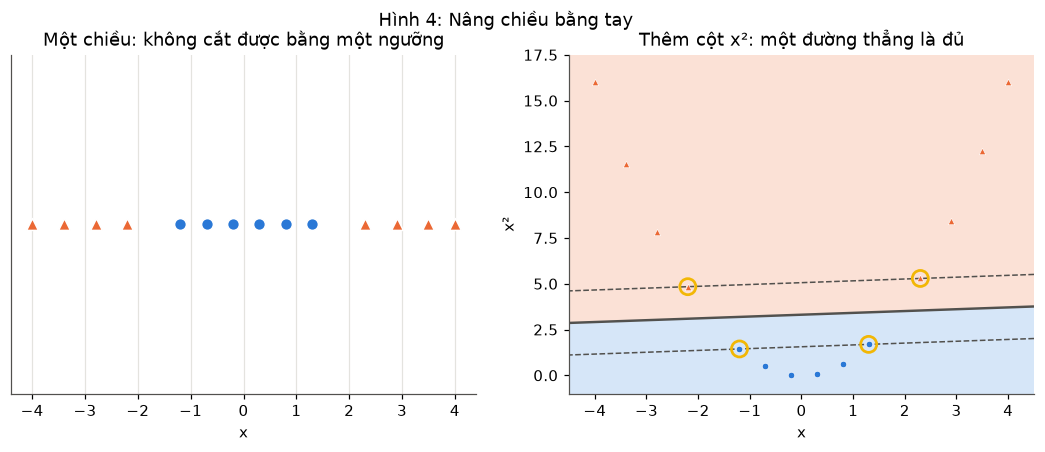

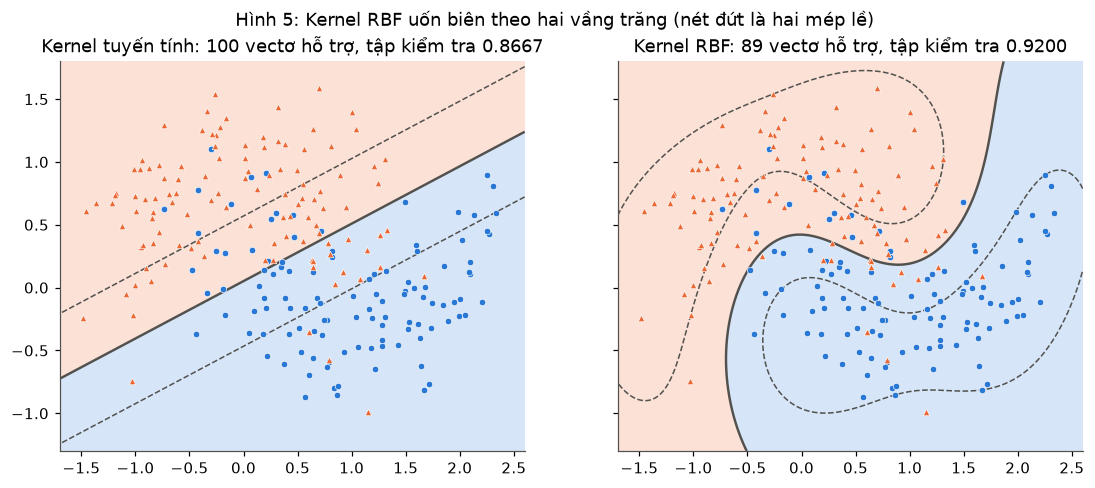

In [8]:
# Hình 4: dữ liệu một chiều, rồi thêm cột x^2
x1d = np.array([-4.0, -3.4, -2.8, -2.2, -1.2, -0.7, -0.2, 0.3, 0.8, 1.3, 2.3, 2.9, 3.5, 4.0])
y1d = (np.abs(x1d) < 1.8).astype(int)
nang = SVC(kernel="linear", C=1000).fit(np.c_[x1d, x1d ** 2], y1d)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for nhan, mau, mk in [(1, MAU_1, "o"), (0, MAU_0, "^")]:
    axs[0].scatter(x1d[y1d == nhan], np.zeros((y1d == nhan).sum()), c=mau, marker=mk, s=60, edgecolor="white")
axs[0].set_yticks([]); axs[0].set_xlabel("x"); axs[0].set_title("Một chiều: không cắt được bằng một ngưỡng")
ve_bien(axs[1], nang, np.c_[x1d, x1d ** 2], y1d, ((-4.5, 4.5), (-1, 17.5)), vecto_ht=nang.support_)
axs[1].set_xlabel("x"); axs[1].set_ylabel("x²"); axs[1].set_title("Thêm cột x²: một đường thẳng là đủ")
fig.suptitle("Hình 4: Nâng chiều bằng tay"); plt.show()

# Hình 5: biên của kernel tuyến tính và kernel RBF trên hai vầng trăng
KHUNG = ((-1.7, 2.6), (-1.3, 1.8))
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, ten in zip(axs, ["SVM kernel tuyen tinh", "SVM kernel RBF"]):
    mh = mo_hinh[ten]
    ve_bien(ax, mh, X_tr, y_tr, KHUNG, ten_cot=["x1", "x2"])
    ax.set_title(f"{'Kernel tuyến tính' if 'tinh' in ten else 'Kernel RBF'}: "
                 f"{len(mh.support_)} vectơ hỗ trợ, tập kiểm tra {mh.score(X_te, y_te):.4f}")
fig.suptitle("Hình 5: Kernel RBF uốn biên theo hai vầng trăng (nét đứt là hai mép lề)"); plt.show()

**Nhận xét.** Khớp tài liệu từng con số.

**Nâng chiều bằng tay.** Trên trục số, ngưỡng tốt nhất chỉ đúng **0.7143**, tức 10/14 điểm (đoán lớp 1 cho mọi x ≤ 1.3 thì sai bốn điểm lớp 0 ở đầu trái). Thêm cột $x^2$, các điểm lớp 1 có $x^2 \le 1.69$, các điểm lớp 0 có $x^2 \ge 4.84$, nên một đường gần nằm ngang tách đúng cả 14 điểm (Hình 4, phải). Trong mặt phẳng $(x, x^2)$ đó là đường thẳng, nhưng chiếu về trục x thì là hai ngưỡng ±1.8, tức một "biên cong".

**Hai vầng trăng.** Kernel tuyến tính và kernel đa thức bậc 3 cùng được **0.8667**, hồi quy logistic 0.8533; kernel RBF được **0.9200**, ngang KNN với k = 13 của bài 4. Hình 5 cho thấy biên tuyến tính chỉ là một đường chéo cắt ngang hai đầu móc của hai vầng trăng, còn biên RBF uốn theo khe giữa hai vầng trăng, và hai mép lề cũng cong theo.

SVM kernel RBF giữ **89 vectơ hỗ trợ trên 225 điểm học** (khoảng 40%). Khi dự đoán, chỉ 89 điểm này bỏ phiếu, mỗi phiếu nặng nhẹ theo $K(x, z)$, tức theo độ gần với điểm mới. Kernel tuyến tính lại cần tới 100 vectơ hỗ trợ: biên thẳng để rất nhiều điểm nằm trong lề hoặc sai phía.

## 4. Chọn C và gamma (`code/g4_chon_tham_so.py`)

Gamma nhỏ: mỗi vectơ hỗ trợ ảnh hưởng xa, biên mượt. Gamma lớn: mỗi vectơ hỗ trợ chỉ ảnh hưởng quanh nó, biên gồ ghề.

In [9]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.svm import SVC

df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

print("gamma   tap hoc   tap kiem tra   so vecto HT")
for g in [0.1, 1, 10, 100]:
    mh = SVC(kernel="rbf", gamma=g).fit(X_tr, y_tr)
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {g:5}  {a_hoc:.4f}    {a_kt:.4f}         "
          f"{len(mh.support_)}")
print()

# Dò lưới: thử mọi cặp bằng kiểm định chéo 5 phần, chỉ trên tập học
luoi = {"C": [0.1, 1, 10, 100], "gamma": [0.01, 0.1, 1, 10]}
tim = GridSearchCV(SVC(kernel="rbf"), luoi, cv=5)
tim.fit(X_tr, y_tr)

bang = pd.DataFrame(tim.cv_results_["params"])
bang["diem"] = tim.cv_results_["mean_test_score"]
print("Diem kiem dinh cheo, hang la C, cot la gamma")
print(bang.pivot(index="C", columns="gamma",
                 values="diem").round(4).to_string())
print()

print("Cap tot nhat:", tim.best_params_)
print(f"Diem kiem dinh cheo: {tim.best_score_:.4f}")
# GridSearchCV đã tự học lại với cặp tốt nhất trên toàn tập học
print(f"Accuracy tren tap kiem tra: {tim.score(X_te, y_te):.4f}")

gamma   tap hoc   tap kiem tra   so vecto HT
    0.1  0.8356    0.8533         113
      1  0.8711    0.9200         88
     10  0.8978    0.9067         128
    100  0.9422    0.8133         217



Diem kiem dinh cheo, hang la C, cot la gamma
gamma   0.01    0.10    1.00    10.00
C                                    
0.1    0.6578  0.8044  0.8444  0.8578
1.0    0.8044  0.8178  0.8667  0.8667
10.0   0.8178  0.8400  0.8711  0.8311
100.0  0.8178  0.8533  0.8711  0.7467

Cap tot nhat: {'C': 10, 'gamma': 1}
Diem kiem dinh cheo: 0.8711
Accuracy tren tap kiem tra: 0.9200


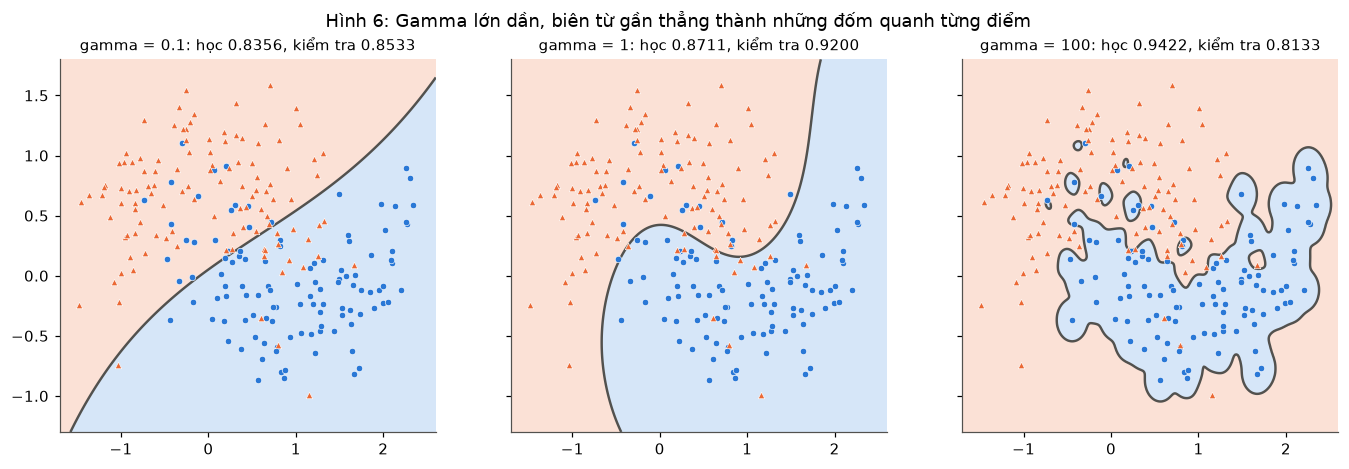

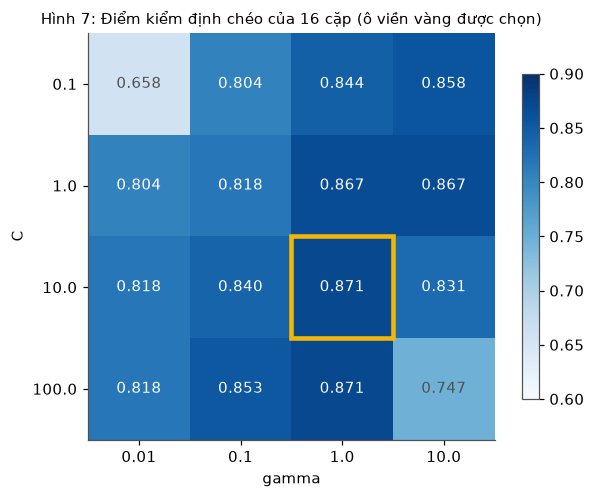

In [10]:
# Hình 6: biên của kernel RBF với ba giá trị gamma, cùng C = 1
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, g in zip(axs, [0.1, 1, 100]):
    mh = SVC(kernel="rbf", gamma=g).fit(X_tr, y_tr)
    ve_bien(ax, mh, X_tr, y_tr, KHUNG, ten_cot=["x1", "x2"], le=False)
    ax.set_title(f"gamma = {g}: học {mh.score(X_tr, y_tr):.4f}, kiểm tra {mh.score(X_te, y_te):.4f}", fontsize=10)
fig.suptitle("Hình 6: Gamma lớn dần, biên từ gần thẳng thành những đốm quanh từng điểm"); plt.show()

# Hình 7: bản đồ nhiệt điểm kiểm định chéo của 16 cặp
bd = bang.pivot(index="C", columns="gamma", values="diem")
fig, ax = plt.subplots(figsize=(6.5, 4.8))
anh = ax.imshow(bd.values, cmap="Blues", vmin=0.6, vmax=0.9)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{bd.values[i, j]:.3f}", ha="center", va="center",
                color="white" if bd.values[i, j] > 0.8 else MAU_CHU, fontsize=10)
i_tot = list(bd.index).index(tim.best_params_["C"]); j_tot = list(bd.columns).index(tim.best_params_["gamma"])
ax.add_patch(plt.Rectangle((j_tot - 0.5, i_tot - 0.5), 1, 1, fill=False, edgecolor=MAU_HT, lw=3))
ax.set_xticks(range(4), [str(g) for g in bd.columns]); ax.set_yticks(range(4), [str(c) for c in bd.index])
ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.grid(False); fig.colorbar(anh, ax=ax, shrink=0.8)
ax.set_title("Hình 7: Điểm kiểm định chéo của 16 cặp (ô viền vàng được chọn)", fontsize=10); plt.show()

**Nhận xét.** Cả hai bảng khớp tài liệu từng con số.

**Gamma** (Hình 6, cùng C = 1):
- Gamma = 0.1: mỗi vectơ hỗ trợ ảnh hưởng rất xa, biên gần như một đường cong thoải; tập học 0.8356, tập kiểm tra 0.8533. Mô hình quá đơn giản (cẩu thả).
- Gamma = 1: biên uốn theo khe giữa hai vầng trăng, tập kiểm tra **0.9200**, và ít vectơ hỗ trợ nhất (88).
- Gamma = 100: biên thành những đốm nhỏ ôm từng cụm điểm, có cả những "đảo" xanh nhỏ xíu giữa vùng cam; tập học lên 0.9422 nhưng tập kiểm tra tụt xuống **0.8133**, và **217/225** điểm học thành vectơ hỗ trợ. Mô hình học vẹt.

Số vectơ hỗ trợ đi theo hình chữ U (113, 88, 128, 217): biên quá thẳng thì nhiều điểm nằm trong lề, biên quá gồ ghề thì mỗi điểm phải tự giữ vùng của mình.

**Dò lưới** (Hình 7). Cặp tốt nhất là **C = 10, gamma = 1**, điểm kiểm định chéo **0.8711**; cặp C = 100, gamma = 1 cũng được đúng 0.8711 và `GridSearchCV` chọn cặp đứng trước. Góc trái trên (cả hai nhỏ) chỉ 0.6578, góc phải dưới (cả hai lớn) tụt về 0.7467 vì học vẹt. Đường chéo từ trái dưới lên phải trên cho thấy C và gamma bù nhau: gamma nhỏ cần C lớn để biên đủ cong, gamma lớn cần C nhỏ để biên bớt gồ ghề. Đó là lý do phải dò từng cặp chứ không dò riêng từng tham số. `GridSearchCV` tự học lại với cặp tốt nhất trên toàn tập học, chấm tập kiểm tra một lần được **0.9200**, khớp tài liệu.

## 5. Nhận dạng chữ số viết tay (`code/g5_chu_so.py`)

Mỗi ảnh 8 × 8 ô là một dòng 64 cột, độ sáng từ 0 tới 16; nhãn là chữ số 0 tới 9 (10 lớp, `SVC` tự học 45 SVM một chọi một).

In [11]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
print("Kich thuoc X:", X.shape)
print("Do sang nho nhat va lon nhat:", X.min(), X.max())
print("So anh moi chu so:", np.bincount(y))
print()

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

svm = SVC(kernel="rbf").fit(X_tr, y_tr)
du_doan = svm.predict(X_te)
print(f"SVM kernel RBF: accuracy {accuracy_score(y_te, du_doan):.4f}")
print("So vecto ho tro:", len(svm.support_), "tren", len(X_tr), "anh")
sai = np.flatnonzero(du_doan != y_te)
print("So anh doan sai:", len(sai), "tren", len(y_te))
for i in sai:
    print(f"  anh {i:3d}: that la {y_te[i]}, doan la {du_doan[i]}")
print()

# So với các mô hình đã học
mo_hinh = {
    "SVM co chuan hoa": make_pipeline(StandardScaler(), SVC()),
    "KNN, k = 5": KNeighborsClassifier(),
    "Logistic co chuan hoa": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000)),
}
print("Cac mo hinh khac, accuracy tren tap kiem tra")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, mh.predict(X_te))
    print(f"  {ten:22s} {acc:.4f}")

Kich thuoc X: (1797, 64)
Do sang nho nhat va lon nhat: 0.0 16.0
So anh moi chu so: [178 182 177 183 181 182 181 179 174 180]

SVM kernel RBF: accuracy 0.9911
So vecto ho tro: 626 tren 1347 anh
So anh doan sai: 4 tren 450
  anh   6: that la 9, doan la 3
  anh  18: that la 8, doan la 1
  anh 161: that la 4, doan la 8
  anh 428: that la 7, doan la 9

Cac mo hinh khac, accuracy tren tap kiem tra
  SVM co chuan hoa       0.9778
  KNN, k = 5             0.9867
  Logistic co chuan hoa  0.9711


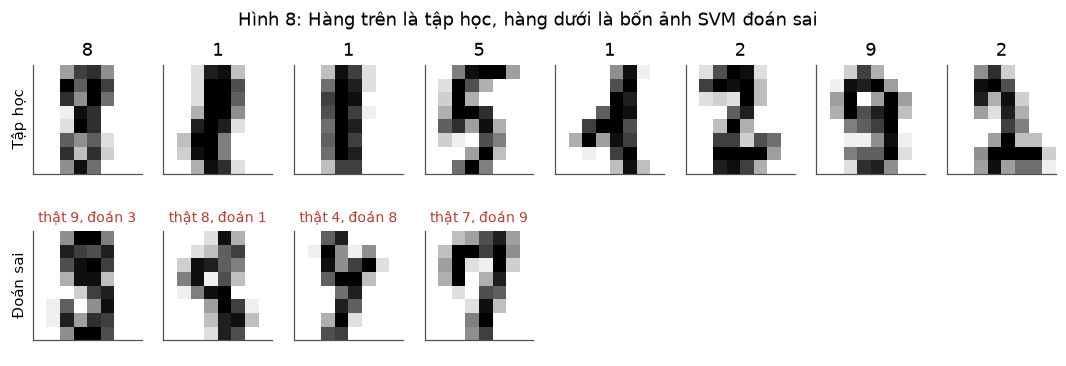

So o co do lech chuan bang 0: 4
So o co do lech chuan nho hon 1: 16
Do lech chuan lon nhat: 6.56


In [12]:
# Hình 8: tám ảnh đầu của tập học, và bốn ảnh SVM đoán sai trên tập kiểm tra
fig, axs = plt.subplots(2, 8, figsize=(12, 3.6))
for k, ax in enumerate(axs[0]):
    ax.imshow(X_tr[k].reshape(8, 8), cmap="gray_r"); ax.set_title(str(y_tr[k]))
for ax in axs[1]:
    ax.axis("off")
for ax, i in zip(axs[1], sai):
    ax.axis("on"); ax.imshow(X_te[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"thật {y_te[i]}, đoán {du_doan[i]}", fontsize=9, color="#c0392b")
for ax in axs.ravel():
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
axs[0, 0].set_ylabel("Tập học"); axs[1, 0].set_ylabel("Đoán sai")
fig.suptitle("Hình 8: Hàng trên là tập học, hàng dưới là bốn ảnh SVM đoán sai"); plt.show()

# Độ lệch chuẩn của 64 ô: các ô ở mép gần như luôn trắng
do_lech = X_tr.std(axis=0)
print("So o co do lech chuan bang 0:", (do_lech == 0).sum())
print("So o co do lech chuan nho hon 1:", (do_lech < 1).sum())
print("Do lech chuan lon nhat:", do_lech.max().round(2))

**Nhận xét.** Khớp tài liệu từng con số. Bộ có 1797 ảnh, 64 cột, độ sáng từ 0 tới 16; mười chữ số có từ 174 tới 183 ảnh, gần cân bằng, nên accuracy là thước đo hợp lý.

SVM kernel RBF để mặc định (`SVC(kernel="rbf")`, tức `SVC()`, C = 1, gamma = "scale", không chuẩn hoá, chia 75/25 với `random_state=17`, `stratify=y`) đạt **0.9911**, chỉ sai **4/450** ảnh: ảnh 6 (9 đoán 3), ảnh 18 (8 đoán 1), ảnh 161 (4 đoán 8), ảnh 428 (7 đoán 9), giữ **626 vectơ hỗ trợ trên 1347 ảnh học**. Hàng dưới của Hình 8 cho thấy cả bốn ảnh đều viết khó đọc, ví dụ chữ 7 có nét ngang khép kín thành vòng giống chữ 9. Với 10 lớp, `SVC` tự học 45 SVM một chọi một và cho chúng bỏ phiếu, không cần viết thêm mã.

So với các mô hình khác: KNN k = 5 được **0.9867**, hồi quy logistic có chuẩn hoá **0.9711**, và **SVM có chuẩn hoá lại kém hơn, chỉ 0.9778**. Ba dòng in cuối giải thích: 4 ô có độ lệch chuẩn bằng 0 (luôn trắng) và 16 ô có độ lệch chuẩn dưới 1, trong khi ô lớn nhất là 6.56. Mọi cột đã cùng thang đo 0 tới 16; chuẩn hoá chia cho những độ lệch chuẩn rất nhỏ ở mép ảnh nên phóng to các ô gần như vô nghĩa (thỉnh thoảng có một chấm mực lạc) lên ngang các ô giữa ảnh. Ngược với mục 3: chuẩn hoá là để đưa các cột *khác* thang đo về cùng thang, không phải luôn luôn có ích.

---
# Bài tập

Mã của từng bài nằm trong `baitap06/baiN.py`; ô bên dưới chạy đúng mã đó.

## Bài tập 1: Tính tay khoảng cách tới ranh giới
Dùng $w_1, w_2, b$ in ra ở mục 2, tự tính $f(x)$ cho hai điểm (3, 3) và (5, 4.5) bằng phép nhân và cộng, không dùng `decision_function`. Khoảng cách từ một điểm tới đường ranh giới là $|f(x)| / \sqrt{w_1^2 + w_2^2}$. Tính khoảng cách của hai điểm trên và của ba vectơ hỗ trợ. Vì sao khoảng cách của ba vectơ hỗ trợ bằng đúng một nửa độ rộng lề?

In [13]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

# Ba hệ số in ra ở mục 2 của đề
w1, w2, b = -0.831, -0.355, 4.820
do_dai_w = np.sqrt(w1 ** 2 + w2 ** 2)
do_rong_le = 2 / do_dai_w
print(f"|w| = sqrt({w1}^2 + {w2}^2) = {do_dai_w:.4f}")
print(f"Do rong le = 2 / |w| = {do_rong_le:.4f}, nua do rong le = {do_rong_le / 2:.4f}")
print()


def f_tay(x1, x2):
    """f(x) = w1*x1 + w2*x2 + b, tinh bang phep nhan va cong."""
    return w1 * x1 + w2 * x2 + b


# Hai điểm mới và ba vectơ hỗ trợ (toạ độ lấy từ kết quả của g1)
cac_diem = [
    ("diem moi (3, 3)    ", 3.0, 3.0),
    ("diem moi (5, 4.5)  ", 5.0, 4.5),
]

# Toạ độ đầy đủ của ba vectơ hỗ trợ: sinh lại đúng 24 điểm của mục 2
X, y = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]],
                  cluster_std=0.9, random_state=0)
y = 1 - y
svm = SVC(kernel="linear", C=1000).fit(X, y)
for i in svm.support_:
    cac_diem.append((f"vecto HT diem {i:2d}  ", X[i, 0], X[i, 1]))

# Cột cuối dùng w, b chưa làm tròn của máy, để thấy sai số do làm tròn
w_may = np.linalg.norm(svm.coef_[0])
print(f"Nua do rong le theo he so chua lam tron: {1 / w_may:.4f}")
print()
print("                       x1     x2    f(x) tinh tay  khoang cach   f(x) may  khoang cach may")
for ten, x1, x2 in cac_diem:
    f = f_tay(x1, x2)
    kc = abs(f) / do_dai_w
    f_may = svm.decision_function([[x1, x2]])[0]
    print(f"  {ten} {x1:5.2f}  {x2:5.2f}    {f:+7.3f}       {kc:7.4f}     {f_may:+7.3f}     {abs(f_may) / w_may:7.4f}")
print()

# Phép tính chi tiết cho hai điểm mới
for x1, x2 in [(3.0, 3.0), (5.0, 4.5)]:
    f = f_tay(x1, x2)
    print(f"f({x1}, {x2}) = ({w1})*{x1} + ({w2})*{x2} + {b} = {f:+.3f};"
          f"  khoang cach = {abs(f):.3f} / {do_dai_w:.4f} = {abs(f) / do_dai_w:.4f}")

|w| = sqrt(-0.831^2 + -0.355^2) = 0.9037
Do rong le = 2 / |w| = 2.2132, nua do rong le = 1.1066

Nua do rong le theo he so chua lam tron: 1.1063

                       x1     x2    f(x) tinh tay  khoang cach   f(x) may  khoang cach may
  diem moi (3, 3)      3.00   3.00     +1.262        1.3966      +1.262      1.3958
  diem moi (5, 4.5)    5.00   4.50     -0.932        1.0319      -0.933      1.0325
  vecto HT diem 18    5.20   4.22     -0.999        1.1057      -1.000      1.1064
  vecto HT diem 10    2.88   4.02     +1.000        1.1067      +1.000      1.1062
  vecto HT diem 13    3.59   2.36     +1.001        1.1075      +1.000      1.1065

f(3.0, 3.0) = (-0.831)*3.0 + (-0.355)*3.0 + 4.82 = +1.262;  khoang cach = 1.262 / 0.9037 = 1.3966
f(5.0, 4.5) = (-0.831)*5.0 + (-0.355)*4.5 + 4.82 = -0.932;  khoang cach = 0.932 / 0.9037 = 1.0319


**Nhận xét.** Tính tay với ba hệ số đã làm tròn 3 chữ số:
- $f(3, 3) = -0.831 \cdot 3 - 0.355 \cdot 3 + 4.820 = +1.262$, khoảng cách $1.262 / 0.9037 = 1.3966$.
- $f(5, 4.5) = -0.831 \cdot 5 - 0.355 \cdot 4.5 + 4.820 = -0.932$, khoảng cách $0.932 / 0.9037 = 1.0319$.

Kết quả trùng `decision_function` (+1.262 và −0.933; chênh 0.001 ở điểm thứ hai do làm tròn hệ số). Điểm (5, 4.5) cách ranh giới 1.03, nhỏ hơn nửa lề 1.106, nên nó nằm trong lề như mục 2 đã nói.

Ba vectơ hỗ trợ cách ranh giới **1.1057, 1.1067, 1.1075**, còn nửa độ rộng lề là $1/\lVert w \rVert$ = 1.1066 (hệ số làm tròn) hay **1.1063** (hệ số chưa làm tròn, đúng bằng 2.2126 / 2). Dùng hệ số chưa làm tròn thì ba khoảng cách là 1.1064, 1.1062, 1.1065: phần lệch còn lại ở chữ số thứ tư là sai số cho phép của bộ giải (cùng lý do $b$ lệch 0.001 ở mục 2).

**Vì sao đúng một nửa độ rộng lề?** Vectơ hỗ trợ là những điểm nằm trên mép lề, tức có $|f(x)| = 1$. Khoảng cách tới ranh giới là $|f(x)| / \lVert w \rVert = 1 / \lVert w \rVert$. Độ rộng lề là khoảng cách giữa hai mép $f = 1$ và $f = -1$, bằng $2 / \lVert w \rVert$, và ranh giới $f = 0$ nằm chính giữa. Nói ngược lại: SVM *định nghĩa* thang đo của $w$ sao cho các điểm gần ranh giới nhất có $|f| = 1$, rồi tối đa $2/\lVert w \rVert$, tức đẩy ranh giới ra xa các điểm gần nhất của **cả hai** lớp một khoảng bằng nhau.

## Bài tập 2: Thêm một điểm
Thêm vào 24 điểm của mục 2 một điểm lớp 1 tại (−1, −1), học lại và in $w_1, w_2, b$. Sau đó bỏ điểm đó, thay bằng một điểm lớp 1 tại (4.5, 4), học lại và in lần nữa. Lần nào đường ranh giới thay đổi? Giải thích bằng khái niệm vectơ hỗ trợ.

In [14]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

X, y = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]],
                  cluster_std=0.9, random_state=0)
y = 1 - y


def hoc_va_in(ten, X, y):
    svm = SVC(kernel="linear", C=1000).fit(X, y)
    w, b = svm.coef_[0], svm.intercept_[0]
    print(ten)
    print(f"  w1 = {w[0]:.3f}, w2 = {w[1]:.3f}, b = {b:.3f},"
          f" do rong le = {2 / np.linalg.norm(w):.4f}")
    print("  vecto ho tro:", ", ".join(
        f"diem {i} ({X[i, 0]:.2f}, {X[i, 1]:.2f}) lop {y[i]}" for i in svm.support_))
    return svm


goc = hoc_va_in("24 diem ban dau", X, y)
print()

# Trước khi học lại, xem điểm mới nằm đâu so với đường ranh giới cũ
for diem in [(-1.0, -1.0), (4.5, 4.0)]:
    f = goc.decision_function([diem])[0]
    print(f"Diem moi {diem}, lop 1: f(x) theo duong cu = {f:+.3f}")
print()

# Lần 1: điểm lớp 1 tại (-1, -1), nằm sâu trong phía lớp 1
X_a = np.vstack([X, [[-1.0, -1.0]]])
y_a = np.append(y, 1)
hoc_va_in("Them diem lop 1 tai (-1, -1)  (diem moi la diem 24)", X_a, y_a)
print()

# Lần 2: bỏ điểm đó, thay bằng điểm lớp 1 tại (4.5, 4), nằm trong lề cũ
X_b = np.vstack([X, [[4.5, 4.0]]])
y_b = np.append(y, 1)
hoc_va_in("Thay bang diem lop 1 tai (4.5, 4)  (diem moi la diem 24)", X_b, y_b)

24 diem ban dau
  w1 = -0.831, w2 = -0.355, b = 4.820, do rong le = 2.2126
  vecto ho tro: diem 18 (5.20, 4.22) lop 0, diem 10 (2.88, 4.02) lop 1, diem 13 (3.59, 2.36) lop 1

Diem moi (-1.0, -1.0), lop 1: f(x) theo duong cu = +6.007
Diem moi (4.5, 4.0), lop 1: f(x) theo duong cu = -0.340

Them diem lop 1 tai (-1, -1)  (diem moi la diem 24)
  w1 = -0.831, w2 = -0.355, b = 4.820, do rong le = 2.2126
  vecto ho tro: diem 18 (5.20, 4.22) lop 0, diem 10 (2.88, 4.02) lop 1, diem 13 (3.59, 2.36) lop 1

Thay bang diem lop 1 tai (4.5, 4)  (diem moi la diem 24)
  w1 = -2.603, w2 = -0.807, b = 15.941, do rong le = 0.7339
  vecto ho tro: diem 18 (5.20, 4.22) lop 0, diem 24 (4.50, 4.00) lop 1


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


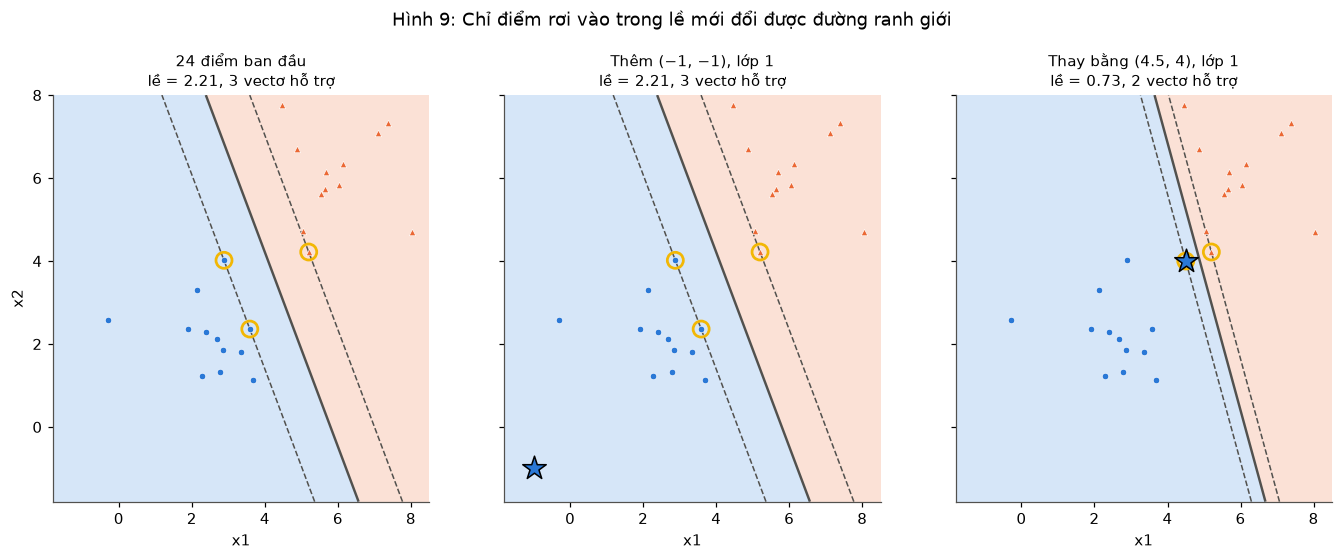

In [15]:
# Hình 9: ba lần học, điểm thêm vào đánh dấu bằng ngôi sao
fig, axs = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for ax, (ten, Xi, yi) in zip(axs, [("24 điểm ban đầu", X, y),
                                   ("Thêm (−1, −1), lớp 1", X_a, y_a),
                                   ("Thay bằng (4.5, 4), lớp 1", X_b, y_b)]):
    mh = SVC(kernel="linear", C=1000).fit(Xi, yi)
    ve_bien(ax, mh, Xi, yi, ((-1.8, 8.5), (-1.8, 8)), vecto_ht=mh.support_)
    if len(Xi) > 24:
        ax.scatter(*Xi[24], marker="*", s=260, c=MAU_1, edgecolor="black", zorder=5)
    ax.set_title(f"{ten}\nlề = {2 / np.linalg.norm(mh.coef_[0]):.2f}, {len(mh.support_)} vectơ hỗ trợ", fontsize=10)
    ax.set_xlabel("x1")
axs[0].set_ylabel("x2")
fig.suptitle("Hình 9: Chỉ điểm rơi vào trong lề mới đổi được đường ranh giới", y=1.04); plt.show()

**Nhận xét.**

**Thêm (−1, −1), lớp 1: đường ranh giới không đổi chút nào** ($w_1 = -0.831$, $w_2 = -0.355$, $b = 4.820$, lề 2.2126, vẫn đúng ba vectơ hỗ trợ cũ). Theo đường cũ, điểm này có $f = +6.007$: đúng phía lớp 1 và cách xa mép lề ($> 1$). Nó thoả ràng buộc mà không cần "đẩy", nên hệ số đối ngẫu của nó bằng 0 và nó không phải vectơ hỗ trợ. Như mục 2 đã thấy, đường ranh giới chỉ do các vectơ hỗ trợ quyết định; thêm bao nhiêu điểm nằm ngoài lề, đúng phía, cũng không làm nó thay đổi.

**Thay bằng (4.5, 4), lớp 1: đường ranh giới thay đổi hẳn.** Theo đường cũ, điểm này có $f = -0.340$: nằm trong lề và còn ở **sai phía** (bị đoán lớp 0). Với C = 1000 (gần như lề cứng), SVM phải dời ranh giới để xếp đúng nó: $w_1 = -2.603$, $w_2 = -0.807$, $b = 15.941$, lề co từ 2.21 xuống **0.73**. Giờ chỉ còn **2 vectơ hỗ trợ**: điểm mới và điểm 18 (lớp 0, (5.20, 4.22)), là cặp điểm khác lớp gần nhau nhất; hai vectơ hỗ trợ cũ của lớp 1 (điểm 10, 13) thành điểm ngoài lề. Hình 9 cho thấy con đường giữa hai lớp bị bóp hẹp và xoay dốc hơn để luồn qua giữa hai điểm đó.

Bài học: một điểm chỉ ảnh hưởng tới SVM khi nó rơi vào trong lề hoặc sai phía, tức khi nó *trở thành* vectơ hỗ trợ. Mặt trái là với lề cứng (C lớn), một điểm duy nhất như vậy (có thể là nhiễu) đủ làm lề hẹp đi 3 lần. Đó là lý do mục 3 dùng lề mềm với C vừa phải.

## Bài tập 3: Kernel đa thức
Trên bộ hai vầng trăng, thử `SVC(kernel="poly", degree=d)` với d bằng 2, 3 và 4, có chuẩn hoá bằng `make_pipeline`. Với mỗi bậc, dò C trong 0.1, 1, 10, 100 bằng `GridSearchCV`. Bậc nào tốt nhất? Có vượt được kernel RBF ở mục 5 không?

In [16]:
import pandas as pd
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Tên tham số trong pipeline phải ghi kèm tên bước: "svc__C"
luoi = {"svc__C": [0.1, 1, 10, 100]}
print("Bac   C tot nhat   kiem dinh cheo   tap kiem tra   so vecto HT")
for d in [2, 3, 4]:
    pipe = make_pipeline(StandardScaler(), SVC(kernel="poly", degree=d))
    tim = GridSearchCV(pipe, luoi, cv=5).fit(X_tr, y_tr)
    svm = tim.best_estimator_[-1]
    print(f"  {d}     {tim.best_params_['svc__C']:6}        {tim.best_score_:.4f}"
          f"          {tim.score(X_te, y_te):.4f}        {len(svm.support_)}")
    diem = tim.cv_results_["mean_test_score"]
    print("      diem theo C:", ", ".join(
        f"C={c}: {s:.4f}" for c, s in zip(luoi["svc__C"], diem)))
print()

# Bậc chẵn với coef0 = 0 cho K(x, z) = K(-x, z), nên f(x) = f(-x).
# Thử lại với coef0 = 1 để kernel có cả các số hạng bậc lẻ.
print("Them coef0 = 1 (mac dinh coef0 = 0)")
print("Bac   C tot nhat   kiem dinh cheo   tap kiem tra")
for d in [2, 3, 4]:
    pipe = make_pipeline(StandardScaler(), SVC(kernel="poly", degree=d, coef0=1))
    tim = GridSearchCV(pipe, luoi, cv=5).fit(X_tr, y_tr)
    print(f"  {d}     {tim.best_params_['svc__C']:6}        {tim.best_score_:.4f}"
          f"          {tim.score(X_te, y_te):.4f}")
print()

# Kiểm tra tính đối xứng: lật mỗi điểm qua tâm dữ liệu (sau chuẩn hoá là x -> -x)
bac2 = make_pipeline(StandardScaler(), SVC(kernel="poly", degree=2)).fit(X_tr, y_tr)
lat = 2 * X_tr.mean() - X_tr
giong = abs(bac2.decision_function(X_tr) - bac2.decision_function(lat)).max()
print(f"Bac 2, coef0 = 0: |f(x) - f(-x)| lon nhat tren tap hoc = {giong:.2e}")
print()

# Kernel RBF của mục 5 (C = 10, gamma = 1, không chuẩn hoá) để so sánh
rbf = GridSearchCV(SVC(kernel="rbf"),
                   {"C": [0.1, 1, 10, 100], "gamma": [0.01, 0.1, 1, 10]},
                   cv=5).fit(X_tr, y_tr)
print(f"Kernel RBF muc 5: {rbf.best_params_}, kiem dinh cheo {rbf.best_score_:.4f},"
      f" tap kiem tra {rbf.score(X_te, y_te):.4f}")

Bac   C tot nhat   kiem dinh cheo   tap kiem tra   so vecto HT
  2          1        0.5422          0.5067        223
      diem theo C: C=0.1: 0.5067, C=1: 0.5422, C=10: 0.5378, C=100: 0.5378


  3          1        0.8178          0.8267        112
      diem theo C: C=0.1: 0.8133, C=1: 0.8178, C=10: 0.8000, C=100: 0.8000


  4        100        0.5156          0.4800        218
      diem theo C: C=0.1: 0.5067, C=1: 0.5111, C=10: 0.5111, C=100: 0.5156

Them coef0 = 1 (mac dinh coef0 = 0)
Bac   C tot nhat   kiem dinh cheo   tap kiem tra


  2        0.1        0.8178          0.8533


  3          1        0.8578          0.9333


  4          1        0.8711          0.9200

Bac 2, coef0 = 0: |f(x) - f(-x)| lon nhat tren tap hoc = 5.07e-14



Kernel RBF muc 5: {'C': 10, 'gamma': 1}, kiem dinh cheo 0.8711, tap kiem tra 0.9200


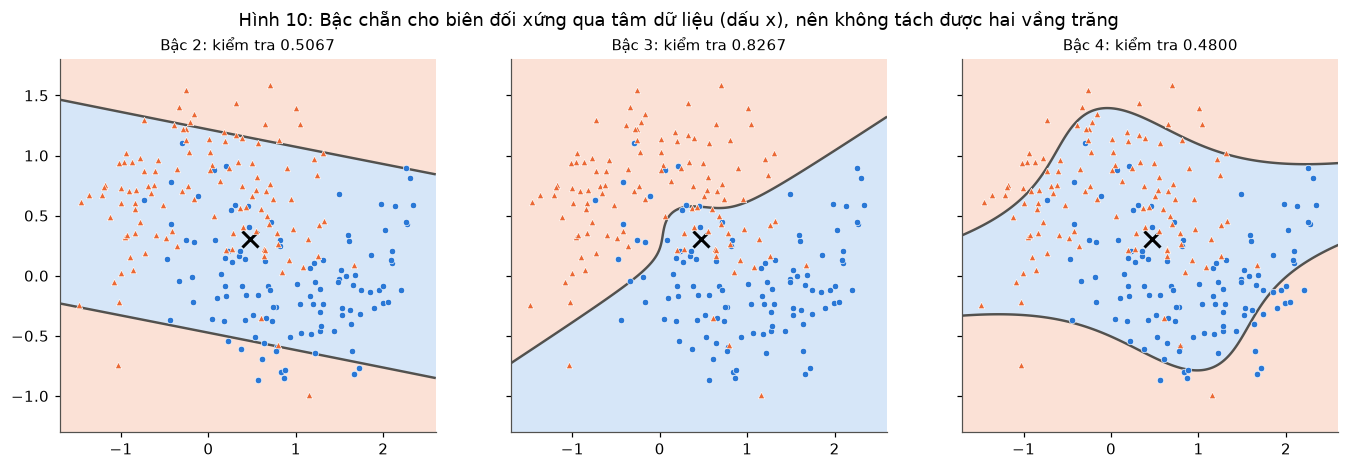

In [17]:
# Hình 10: biên của kernel đa thức bậc 2, 3, 4 (C = 1, coef0 mặc định bằng 0)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, d in zip(axs, [2, 3, 4]):
    mh = make_pipeline(StandardScaler(), SVC(kernel="poly", degree=d)).fit(X_tr, y_tr)
    ve_bien(ax, mh, X_tr, y_tr, KHUNG, ten_cot=["x1", "x2"], le=False)
    ax.plot(*X_tr.mean(), "kx", ms=10, mew=2)
    ax.set_title(f"Bậc {d}: kiểm tra {mh.score(X_te, y_te):.4f}", fontsize=10)
fig.suptitle("Hình 10: Bậc chẵn cho biên đối xứng qua tâm dữ liệu (dấu x), nên không tách được hai vầng trăng"); plt.show()

**Nhận xét.** Với `coef0` mặc định bằng 0, **bậc 3 tốt nhất** (C = 1, kiểm định chéo 0.8178, tập kiểm tra 0.8267). Bậc 2 và bậc 4 gần như đoán bừa: kiểm định chéo 0.5422 và 0.5156, tập kiểm tra **0.5067** và **0.4800**, với 223 và 218 trên 225 điểm là vectơ hỗ trợ. Không bậc nào vượt kernel RBF của mục 5 (0.8711 / 0.9200).

**Vì sao bậc chẵn hỏng hẳn?** Kernel đa thức của scikit-learn là $K(x, z) = (\gamma\, x \cdot z + \text{coef0})^d$. Với coef0 = 0 và d chẵn, $K(-x, z) = K(x, z)$, nên $f(-x) = f(x)$: biên đối xứng qua gốc toạ độ, mà sau `StandardScaler` gốc toạ độ chính là tâm dữ liệu. Dòng kiểm tra in ra $|f(x) - f(-x)| \approx 5 \cdot 10^{-14}$, tức bằng nhau tuyệt đối. Bộ hai vầng trăng lại **đối xứng tâm theo kiểu đổi lớp**: vầng trăng lớp 1 chính là vầng trăng lớp 0 quay 180° quanh tâm (dấu x ở Hình 10). Một điểm và ảnh đối xứng của nó gần như luôn khác lớp, nhưng mô hình bậc chẵn buộc phải đoán chúng cùng lớp, nên không thể vượt mức đoán bừa. Hình 10 thấy rõ: biên bậc 2 là hai đường song song đối xứng qua tâm, biên bậc 4 là một dải đối xứng. Bậc lẻ thì $f(-x) - b = -(f(x) - b)$, hợp với kiểu đối xứng đổi lớp này, nên bậc 3 làm được.

Khi đặt `coef0=1` (khai triển có cả các số hạng bậc thấp hơn, cả chẵn lẫn lẻ), mọi bậc đều ổn: bậc 2 được 0.8178 / 0.8533, bậc 3 được 0.8578 / **0.9333**, bậc 4 được **0.8711** / 0.9200. Bậc 3 có tập kiểm tra cao hơn RBF (0.9333 so với 0.9200, hơn 1 điểm trên 75), nhưng điểm kiểm định chéo thấp hơn (0.8578 so với 0.8711); chọn mô hình theo kiểm định chéo thì RBF vẫn là lựa chọn, còn chênh 1 điểm kiểm tra nằm trong dao động ngẫu nhiên. Bậc 4 với coef0 = 1 ngang bằng RBF ở cả hai con số.

Ghi chú: bậc 3 có chuẩn hoá ở đây (0.8267) thấp hơn bậc 3 không chuẩn hoá ở mục 4 (0.8667). Đổi thang đo thì `gamma="scale"` và đa thức đổi theo, nên hai mô hình khác nhau; hai cột của bộ hai vầng trăng vốn cùng thang nên chuẩn hoá không giúp gì.

## Bài tập 4: Dò lưới mịn
Quanh cặp tốt nhất của mục 5, dò lại với C trong 3, 10, 30 và gamma trong 0.3, 1, 3. Điểm kiểm định chéo tốt nhất có cao hơn 0.8711 không? Accuracy trên tập kiểm tra có đổi không? Nhận xét về cái lợi của việc dò thật mịn.

In [18]:
import pandas as pd
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.svm import SVC

df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Lưới thưa của mục 5, để so sánh
thua = GridSearchCV(SVC(kernel="rbf"),
                    {"C": [0.1, 1, 10, 100], "gamma": [0.01, 0.1, 1, 10]},
                    cv=5).fit(X_tr, y_tr)

# Lưới mịn quanh C = 10, gamma = 1
luoi = {"C": [3, 10, 30], "gamma": [0.3, 1, 3]}
min_ = GridSearchCV(SVC(kernel="rbf"), luoi, cv=5).fit(X_tr, y_tr)

bang = pd.DataFrame(min_.cv_results_["params"])
bang["diem"] = min_.cv_results_["mean_test_score"]
bang["lech chuan"] = min_.cv_results_["std_test_score"]
print("Luoi min, diem kiem dinh cheo, hang la C, cot la gamma")
print(bang.pivot(index="C", columns="gamma", values="diem").round(4).to_string())
print()
print("Do lech chuan giua 5 phan, hang la C, cot la gamma")
print(bang.pivot(index="C", columns="gamma", values="lech chuan").round(4).to_string())
print()

print("              cap tot nhat              kiem dinh cheo   tap kiem tra")
for ten, tim in [("Luoi thua", thua), ("Luoi min ", min_)]:
    print(f"  {ten}   {str(tim.best_params_):24s}   {tim.best_score_:.4f}"
          f"           {tim.score(X_te, y_te):.4f}")
print()

# Hai mô hình có đoán khác nhau trên tập kiểm tra không
khac = (thua.predict(X_te) != min_.predict(X_te)).sum()
print("So diem kiem tra hai mo hinh doan khac nhau:", khac, "tren", len(X_te))
print("So lan hoc: luoi thua", 16 * 5, "lan, luoi min", 9 * 5, "lan")

Luoi min, diem kiem dinh cheo, hang la C, cot la gamma
gamma     0.3     1.0     3.0
C                            
3      0.8533  0.8711  0.8667
10     0.8489  0.8711  0.8667
30     0.8622  0.8756  0.8533

Do lech chuan giua 5 phan, hang la C, cot la gamma
gamma     0.3     1.0     3.0
C                            
3      0.0267  0.0089  0.0141
10     0.0218  0.0089  0.0281
30     0.0166  0.0178  0.0361

              cap tot nhat              kiem dinh cheo   tap kiem tra
  Luoi thua   {'C': 10, 'gamma': 1}      0.8711           0.9200
  Luoi min    {'C': 30, 'gamma': 1}      0.8756           0.9200

So diem kiem tra hai mo hinh doan khac nhau: 0 tren 75
So lan hoc: luoi thua 80 lan, luoi min 45 lan


**Nhận xét.** Lưới mịn chọn **C = 30, gamma = 1**, điểm kiểm định chéo **0.8756**, cao hơn 0.8711 của lưới thưa đúng 0.0045, tức chưa tới 1 điểm học trên mỗi phần kiểm định (mỗi phần có 45 điểm, 1 điểm là 0.022, trung bình 5 phần thành 0.0044). **Accuracy tập kiểm tra không đổi, vẫn 0.9200**, và hai mô hình đoán giống hệt nhau trên cả 75 điểm kiểm tra.

Bảng độ lệch chuẩn cho thấy mức dao động giữa 5 phần là 0.009 tới 0.036, lớn hơn nhiều so với 0.0045 vừa "kiếm được". Cả cột gamma = 1 nằm trên một vùng phẳng (0.8711, 0.8711, 0.8756), còn gamma = 0.3 hay 3 chỉ kém 0.005 tới 0.02. Nghĩa là quanh cặp C = 10, gamma = 1, mô hình gần như không nhạy với tham số.

Cái lợi của dò thật mịn vì vậy rất nhỏ: lưới thưa (cách nhau 10 lần) đã tìm đúng vùng tốt, lưới mịn chỉ nhích điểm kiểm định chéo trong phạm vi nhiễu. Dò càng mịn còn có rủi ro chọn tham số vì may mắn trên đúng 5 phần chia này (quá khớp vào kiểm định chéo), mà chi phí lại tăng nhanh: 9 cặp × 5 phần = 45 lần học, thêm một chiều mịn nữa là nhân lên. Cách làm hợp lý là lưới thưa trước, lưới mịn chỉ khi vùng tốt còn dốc rõ rệt.

## Bài tập 5: Chữ số viết tay, những lỗi nào hay gặp
Dùng `confusion_matrix` in bảng nhầm lẫn 10 × 10 của SVM ở mục 6 (hàng là chữ số thật, cột là chữ số đoán). Cho biết những cặp chữ số nào bị nhầm. Vẽ và lưu từng ảnh bị đoán sai bằng `plt.imshow(X_te[i].reshape(8, 8), cmap="gray_r")`, rồi nhận xét vì sao SVM nhầm.

In [19]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Đúng mô hình của mục 6: SVC kernel RBF để mặc định, không chuẩn hoá
svm = SVC(kernel="rbf").fit(X_tr, y_tr)
du_doan = svm.predict(X_te)

bang = confusion_matrix(y_te, du_doan)
print("Bang nham lan, hang la chu so that, cot la chu so doan")
print(pd.DataFrame(bang, index=[f"that {i}" for i in range(10)],
                   columns=[str(i) for i in range(10)]).to_string())
print()
print("Tong duong cheo (doan dung):", np.trace(bang), "tren", bang.sum())
print()

# Các ô ngoài đường chéo khác 0 là các cặp bị nhầm
print("Cac cap bi nham (that -> doan): so anh")
for that in range(10):
    for doan in range(10):
        if that != doan and bang[that, doan] > 0:
            print(f"  {that} -> {doan}: {bang[that, doan]}")
print()

# Vẽ và lưu từng ảnh đoán sai
os.makedirs("anh_doan_sai", exist_ok=True)
sai = np.flatnonzero(du_doan != y_te)
diem_quyet_dinh = svm.decision_function(X_te[sai])
for i, phieu in zip(sai, diem_quyet_dinh):
    fig, ax = plt.subplots(figsize=(2.5, 2.8))
    ax.imshow(X_te[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"anh {i}: that {y_te[i]}, doan {du_doan[i]}", fontsize=9)
    ax.axis("off")
    ten_tep = f"anh_doan_sai/anh_{i}_that{y_te[i]}_doan{du_doan[i]}.png"
    fig.savefig(ten_tep, dpi=120, bbox_inches="tight")
    plt.close(fig)                      # chỉ lưu tệp, không mở cửa sổ
    # decision_function kiểu "ovr": điểm cao nhất là lớp được đoán
    # (phần nguyên xấp xỉ số phiếu thắng trong 45 cặp một chọi một)
    thu_tu = np.argsort(phieu)[::-1]
    hang_that = int(np.flatnonzero(thu_tu == y_te[i])[0]) + 1
    print(f"Da luu {ten_tep}")
    print(f"    ba lop diem cao nhat: " + ", ".join(
        f"{c} ({phieu[c]:.2f})" for c in thu_tu[:3])
        + f"; lop that {y_te[i]} dung hang {hang_that} ({phieu[y_te[i]]:.2f})")

Bang nham lan, hang la chu so that, cot la chu so doan
         0   1   2   3   4   5   6   7   8   9
that 0  45   0   0   0   0   0   0   0   0   0
that 1   0  46   0   0   0   0   0   0   0   0
that 2   0   0  44   0   0   0   0   0   0   0
that 3   0   0   0  46   0   0   0   0   0   0
that 4   0   0   0   0  44   0   0   0   1   0
that 5   0   0   0   0   0  46   0   0   0   0
that 6   0   0   0   0   0   0  45   0   0   0
that 7   0   0   0   0   0   0   0  44   0   1
that 8   0   1   0   0   0   0   0   0  42   0
that 9   0   0   0   1   0   0   0   0   0  44

Tong duong cheo (doan dung): 446 tren 450

Cac cap bi nham (that -> doan): so anh
  4 -> 8: 1
  7 -> 9: 1
  8 -> 1: 1
  9 -> 3: 1

Da luu anh_doan_sai/anh_6_that9_doan3.png
    ba lop diem cao nhat: 3 (9.30), 8 (8.30), 9 (7.26); lop that 9 dung hang 3 (7.26)
Da luu anh_doan_sai/anh_18_that8_doan1.png
    ba lop diem cao nhat: 1 (9.29), 8 (8.29), 4 (7.23); lop that 8 dung hang 2 (8.29)


Da luu anh_doan_sai/anh_161_that4_doan8.png
    ba lop diem cao nhat: 8 (8.29), 9 (8.28), 7 (7.25); lop that 4 dung hang 4 (6.26)
Da luu anh_doan_sai/anh_428_that7_doan9.png
    ba lop diem cao nhat: 9 (9.29), 7 (8.26), 8 (7.24); lop that 7 dung hang 2 (8.26)


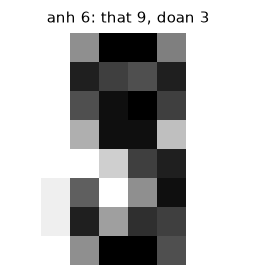

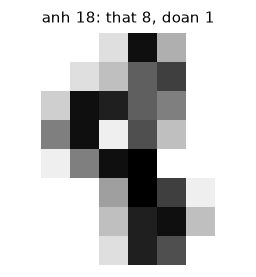

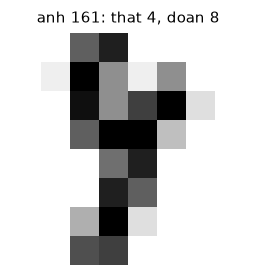

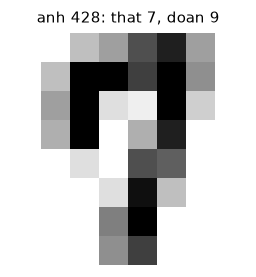

In [20]:
# Bốn ảnh đã lưu trong anh_doan_sai/
import glob
from IPython.display import Image, display
for tep in sorted(glob.glob("anh_doan_sai/*.png"), key=lambda t: int(t.split("_")[3])):
    display(Image(tep, width=180))

**Nhận xét.** Bảng nhầm lẫn có đường chéo 446/450, tức đúng 0.9911 như mục 6. Chỉ có **bốn ô ngoài đường chéo**, mỗi ô bằng 1: 4 → 8, 7 → 9, 8 → 1, 9 → 3. Không cặp nào bị nhầm quá một lần, nên không có "lỗi hệ thống" kiểu SVM luôn lẫn hai chữ số nào đó; các chữ 0, 1, 2, 3, 5, 6 đúng 100%.

`decision_function` (kiểu "ovr" mặc định) cho mỗi lớp một điểm có phần nguyên là số trận thắng trong 9 cặp một chọi một của lớp đó, phần lẻ là độ tự tin. Đọc cùng bốn ảnh đã lưu:
- **Ảnh 6, thật 9 đoán 3**: lớp 3 thắng cả 9 trận, lớp 9 thật chỉ đứng thứ ba (7 trận). Vòng trên của chữ 9 không khép, nét bên trái hở và phần dưới cong ra như chữ 3.
- **Ảnh 18, thật 8 đoán 1**: lớp 1 được 9 trận, lớp 8 được 8, tức chữ 8 chỉ thua đúng trận 8 chọi 1. Chữ 8 viết hẹp và nghiêng, hai vòng gần như dẹt thành một nét dọc giống chữ 1.
- **Ảnh 161, thật 4 đoán 8**: ca khó nhất. Lớp 8 và lớp 9 cùng 8 trận, chỉ hơn nhau ở phần lẻ (8.29 so với 8.28); lớp 4 thật chỉ đứng thứ tư (6 trận). Nét ngang và nét dọc của chữ 4 khép thành vòng kín ở trên, phía dưới là một nét đuôi, giống chữ 9 hoặc 8 hơn là 4.
- **Ảnh 428, thật 7 đoán 9**: lớp 9 được 9 trận, lớp 7 được 8. Nét ngang của chữ 7 cong xuống khép thành vòng nhỏ, đúng hình dạng đầu chữ 9.

Cả bốn lỗi là ảnh mà người đọc cũng phải ngập ngừng. Ở độ phân giải 8 × 8, một ô mực thêm hay bớt là đủ đổi một vòng hở thành vòng kín; SVM chỉ so độ giống nhau từng ô (khoảng cách trong kernel RBF) nên không "hiểu" nét viết.

## Bài tập 6: SVM trên dữ liệu lớn
Tạo dữ liệu bằng `make_classification(n_samples=n, n_features=20, random_state=0)` với n bằng 2000, 5000, 10000 và 20000. Với mỗi cỡ, đo thời gian `.fit` của `SVC()` và của `LinearSVC()` bằng mô đun `time`. Khi dữ liệu tăng gấp đôi, thời gian học của mỗi mô hình tăng khoảng bao nhiêu lần?

In [21]:
import time

from sklearn.datasets import make_classification
from sklearn.svm import SVC, LinearSVC


def do_thoi_gian(lop_mo_hinh, X, y, so_lan=3):
    """Thoi gian .fit nhanh nhat trong so_lan lan do (giay)."""
    ket_qua = []
    for _ in range(so_lan):
        bat_dau = time.perf_counter()
        lop_mo_hinh().fit(X, y)
        ket_qua.append(time.perf_counter() - bat_dau)
    return min(ket_qua)


cac_co = [2000, 5000, 10000, 20000]
thoi_gian = {"SVC": [], "LinearSVC": []}

print("      n    SVC (giay)   LinearSVC (giay)   so vecto HT cua SVC")
for n in cac_co:
    X, y = make_classification(n_samples=n, n_features=20, random_state=0)

    t_svc = do_thoi_gian(SVC, X, y)
    t_lin = do_thoi_gian(LinearSVC, X, y)
    svc = SVC().fit(X, y)

    thoi_gian["SVC"].append(t_svc)
    thoi_gian["LinearSVC"].append(t_lin)
    print(f"  {n:6d}    {t_svc:9.3f}     {t_lin:9.4f}            {len(svc.support_)}")
print()

# Khi n tăng gấp đôi (10000 -> 20000), thời gian tăng bao nhiêu lần
print("Ti le thoi gian giua hai co lien nhau")
print("  co du lieu          gap    SVC    LinearSVC")
for i in range(1, len(cac_co)):
    gap = cac_co[i] / cac_co[i - 1]
    r_svc = thoi_gian["SVC"][i] / thoi_gian["SVC"][i - 1]
    r_lin = thoi_gian["LinearSVC"][i] / thoi_gian["LinearSVC"][i - 1]
    print(f"  {cac_co[i - 1]:5d} -> {cac_co[i]:5d}    {gap:4.1f}   {r_svc:5.2f}    {r_lin:5.2f}")

      n    SVC (giay)   LinearSVC (giay)   so vecto HT cua SVC


    2000        0.047        0.0029            456


    5000        0.202        0.0061            913


   10000        2.866        0.0122            4555


   20000        7.969        0.0273            7448

Ti le thoi gian giua hai co lien nhau
  co du lieu          gap    SVC    LinearSVC
   2000 ->  5000     2.5    4.26     2.13
   5000 -> 10000     2.0   14.21     1.99
  10000 -> 20000     2.0    2.78     2.24


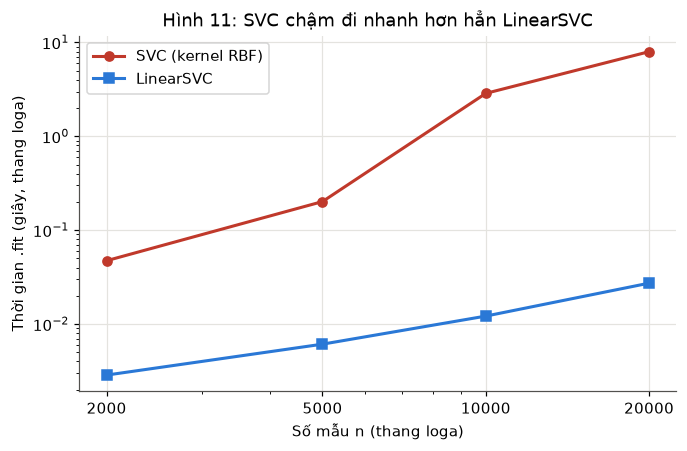

In [22]:
# Hình 11: thời gian học theo cỡ dữ liệu, cả hai trục thang loga
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(cac_co, thoi_gian["SVC"], "o-", color="#c0392b", label="SVC (kernel RBF)")
ax.plot(cac_co, thoi_gian["LinearSVC"], "s-", color=MAU_1, label="LinearSVC")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(cac_co, [str(n) for n in cac_co])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("Số mẫu n (thang loga)"); ax.set_ylabel("Thời gian .fit (giây, thang loga)")
ax.set_title("Hình 11: SVC chậm đi nhanh hơn hẳn LinearSVC"); ax.legend(); plt.show()

**Nhận xét.** Số giây tuyệt đối phụ thuộc máy (ở đây đo với một luồng, lấy lần nhanh nhất trong 3 lần), chỉ nên so tương đối.

- **LinearSVC** tăng gần đúng **gấp đôi** mỗi khi dữ liệu gấp đôi (tỉ lệ khoảng 1.8 tới 2.2 ở hai bước gấp đôi; từ 2000 lên 5000, gấp 2.5 lần dữ liệu, thời gian cũng tăng khoảng 2.1 tới 2.5 lần qua các lần chạy). Thời gian học gần như tỉ lệ thuận với n: mỗi vòng lặp chỉ duyệt qua dữ liệu một lần để cập nhật $w$, không cần so từng cặp điểm.
- **SVC** (kernel RBF) tăng **nhanh hơn hẳn**: từ 10000 lên 20000 gấp khoảng **3 lần**, từ 2000 lên 5000 gấp khoảng 4 lần. Bộ giải của SVC làm việc với ma trận kernel $K(x_i, x_j)$ giữa các cặp điểm, nên chi phí tăng cỡ $n^{1.5}$ tới $n^2$ và còn tăng theo số vectơ hỗ trợ.
- Bước 5000 → 10000 của SVC nhảy vọt khoảng **12 tới 14 lần** (tuỳ lần chạy). Lý do nằm ở dữ liệu chứ không ở thuật toán: `make_classification` với n khác nhau sinh ra các bộ dữ liệu khác nhau, và bộ 10000 mẫu khó tách hơn nhiều, số vectơ hỗ trợ tăng từ 913 lên **4555** (gần một nửa dữ liệu). SVC càng nhiều vectơ hỗ trợ thì càng nhiều vòng lặp và càng nhiều cột kernel phải tính.

Ở n = 20000, SVC chậm hơn LinearSVC gần **300 lần** (vài giây so với vài phần trăm giây), và khoảng cách này còn nới rộng khi n tăng (Hình 11, hai đường dốc khác nhau trên thang loga). Với vài chục nghìn mẫu trở lên, nên thử `LinearSVC` (hoặc SVC trên một mẫu nhỏ) trước, đúng như phụ lục B của đề gợi ý.